## Clustering: Análisis e interpretación

Se integran los cuatro métodos: tipologías legibles, cruces con región/tipo, el segmento cautivo (PQ1), la convergencia
entre métodos, los outliers y la discusión de escalabilidad

### Imports

In [1]:
import os, socket, time, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, Window, functions as F

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.max_columns", 40)

### Utilidades

- Constantes

In [2]:
SECCION, NOTEBOOK = "02_Clustering", "e_analisis"

proyecto = Path.cwd()
while not (proyecto / "docker-compose.yml").exists() and proyecto != proyecto.parent:
    proyecto = proyecto.parent

final_dir = proyecto / "data" / "final"
artef_dir = proyecto / "data" / "artefactos"
clus_dir  = proyecto / "data" / "clustering"
clus_dir.mkdir(parents=True, exist_ok=True)
SUJETOS = {"entidad": "entidad_key", "proveedor": "proveedor_key"}
SEED = 42

out_dir = proyecto / SECCION / "temp" / NOTEBOOK
fig_dir, tab_dir, web_dir = out_dir / "figs", out_dir / "tablas", out_dir / "web"
for d in (fig_dir, tab_dir, web_dir):
    d.mkdir(parents=True, exist_ok=True)

def mostrar_fig(nombre):
    plt.tight_layout()
    plt.savefig(fig_dir / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

def guardar_tabla(df, nombre):
    sdf = spark.createDataFrame(df) if isinstance(df, pd.DataFrame) else df
    sdf.coalesce(1).write.mode("overwrite").parquet(str(tab_dir / nombre))
    sdf.toPandas().to_json(web_dir / f"{nombre}.json", orient="records", force_ascii=False, date_format="iso", indent=1)
    return len(df) if isinstance(df, pd.DataFrame) else sdf.count()

def leer(directorio, nombre):
    return spark.read.parquet(str(directorio / nombre))

- Spark

In [3]:
spark_master = os.environ.get("spark_master", "local[*]")

builder = (SparkSession.builder
           .appName(NOTEBOOK)
           .master(spark_master)
           .config("spark.driver.memory",   os.environ.get("SPARK_DRIVER_MEMORY", "4g"))
           .config("spark.executor.memory", os.environ.get("SPARK_EXECUTOR_MEMORY", "4g"))
           .config("spark.sql.shuffle.partitions", "24")
           .config("spark.ui.showConsoleProgress", "false")
           .config("spark.sql.session.timeZone", "America/Lima")
           .config("spark.sql.execution.arrow.pyspark.enabled", "true"))

if spark_master.startswith("spark://"):
    builder = (builder.config("spark.driver.host", socket.gethostname())
                      .config("spark.driver.bindAddress", "0.0.0.0"))

spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

### Verificación del cluster

In [4]:
sc = spark.sparkContext
estado = sc._jsc.sc().getExecutorMemoryStatus()
print(f"Master        : {sc.master}")
print(f"Executors     : {estado.size() - 1}")
print(f"Cores totales : {sc.defaultParallelism}")
print(f"Memoria driver: {sc._jvm.java.lang.Runtime.getRuntime().maxMemory() / 1024**3:.1f} GB")
print("UI del job    : http://localhost:4040")

Master        : spark://spark-master:7077
Executors     : 0
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

In [5]:
from pyspark.ml.functions import vector_to_array
from sklearn.metrics import adjusted_rand_score

config = json.loads((clus_dir / "config.json").read_text())
MONTO = {"entidad": "monto_adjudicado_total", "proveedor": "monto_total"}
d = {s: leer(clus_dir, f"prep_{s}").join(leer(clus_dir, f"kmeans_{s}"), cfg["key"]).cache() for s, cfg in config.items()}

In [6]:
def rasgos(z, cols, top=3, prefijo=""):
    # describe un punto o un clúster por sus features más alejadas de la media (en desviaciones estándar)
    z = z[cols].astype(float)
    orden = z.abs().sort_values(ascending=False).index[:top]
    return ", ".join(f"{c[len(prefijo):]} {'↑' if z[c] > 0 else '↓'}{abs(z[c]):.1f}σ" for c in orden)

---
### 1. Tipologías (KMeans)

=== entidad


,cluster,n,mediana_procesos,mediana_monto,pct_monto,pct_postor_unico,pct_directa,pct_sin_adjudicar,pct_bienes,pct_obras,share_top_proveedor,pct_actores,rasgos
0,0,1400,16,1505488.62,6.6,0.045,0.019,0.723,0.357,0.277,0.584,51.9,"log_n_proveedores ↓0.7σ, log_n_procesos ↓0.7σ, log_n_familias ↓0.7σ"
1,1,1060,99,15100054.03,82.8,0.064,0.045,0.702,0.461,0.131,0.281,39.3,"log_n_procesos ↑0.9σ, log_n_proveedores ↑0.9σ, log_n_familias ↑0.8σ"
2,2,235,49,7886822.37,10.6,0.378,0.270,0.673,0.298,0.098,0.413,8.7,"pct_postor_unico ↑2.4σ, pct_directa ↑2.2σ, log_postores_promedio ↓0.8σ"


=== proveedor


,cluster,n,mediana_procesos,mediana_monto,pct_monto,n_regiones,pct_postor_unico,pct_directa,pct_consorcio,pct_bienes,pct_obras,share_top_entidad,tasa_exito,compite,pct_actores,rasgos
0,0,534,3,986180.00,9.6,1.425,0.724,0.406,0.0,0.230,0.021,0.818,0.697,1.0,9.1,"pct_postor_unico ↑2.7σ, pct_directa ↑2.0σ, tasa_exito ↑1.3σ"
1,1,1065,12,4080049.00,44.2,6.846,0.055,0.044,0.0,0.704,0.062,0.390,0.250,1.0,18.2,"log_n_procesos ↑1.6σ, log_n_entidades ↑1.6σ, n_regiones ↑1.3σ"
2,2,4266,4,893443.49,46.1,2.103,0.030,0.021,0.0,0.521,0.079,0.672,0.304,1.0,72.7,"log_n_procesos ↓0.4σ, log_n_entidades ↓0.3σ, pct_postor_unico ↓0.3σ"


/tmp/ipykernel_12850/3902243437.py:20: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


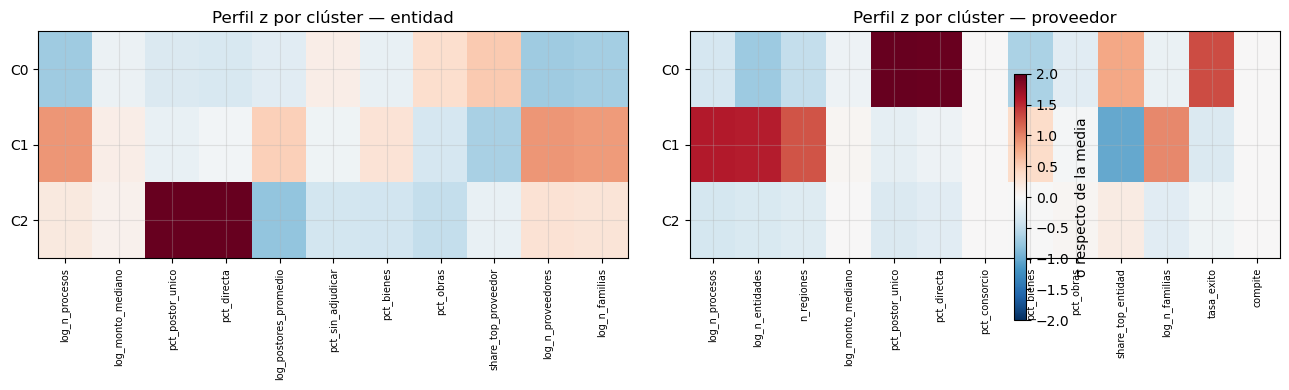

In [7]:
perfiles = {}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for i, (s, cfg) in enumerate(config.items()):
    feats, monto = cfg["feats"], MONTO[s]
    tot = d[s].agg(F.sum(monto)).first()[0]
    p = (d[s].groupBy("cluster").agg(
            F.count("*").alias("n"),
            F.expr("percentile_approx(n_procesos, 0.5)").alias("mediana_procesos"),
            F.expr(f"percentile_approx({monto}, 0.5)").alias("mediana_monto"),
            F.round(100 * F.sum(monto) / F.lit(tot), 1).alias("pct_monto"),
            *[F.round(F.avg(f), 3).alias(f) for f in feats if not f.startswith("log_")])
         .orderBy("cluster").toPandas())
    z = (d[s].withColumn("_z", vector_to_array("features_std")).groupBy("cluster")
             .agg(*[F.avg(F.col("_z")[j]).alias(f) for j, f in enumerate(feats)]).toPandas().set_index("cluster").sort_index())
    p["pct_actores"] = (100 * p.n / p.n.sum()).round(1)
    p["rasgos"] = p.cluster.map(lambda c: rasgos(z.loc[c], feats))
    perfiles[s] = p
    print(f"=== {s}"); display(p)
    im = ax[i].imshow(z.to_numpy(), cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
    ax[i].set_xticks(range(len(feats))); ax[i].set_xticklabels(feats, rotation=90, fontsize=7)
    ax[i].set_yticks(range(len(z))); ax[i].set_yticklabels([f"C{c}" for c in z.index])
    ax[i].set_title(f"Perfil z por clúster — {s}")
fig.colorbar(im, ax=ax, shrink=.8, label="σ respecto de la media")
mostrar_fig("perfiles_z")

#### Nombres de las tipologías (completar tras correr)

| Sujeto | Clúster | Nombre propuesto | Evidencia (rasgos, % actores, % monto) |
|---|---|---|---|
| entidad | C‹›| ‹p. ej. "Grandes compradoras competidas"› | ‹› |
| entidad | C‹›| ‹p. ej. "Cautivas de contratación directa"› | ‹› |
| proveedor | C‹›| ‹p. ej. "Proveedores nacionales multientidad"› | ‹› |
| proveedor | C‹›| ‹p. ej. "Dependientes de un solo cliente"› | ‹› |

### 2. Cruces con región y tipo de proveedor

In [8]:
w = Window.partitionBy("cluster")
reg = (d["entidad"].groupBy("cluster", "region").count()
         .withColumn("pct", F.round(100 * F.col("count") / F.sum("count").over(w), 1))
         .withColumn("rk", F.row_number().over(w.orderBy(F.desc("count")))).where("rk <= 3")
         .orderBy("cluster", "rk").toPandas())
tipo = (d["proveedor"].groupBy("cluster").agg(
            F.count("*").alias("n"),
            F.round(100 * F.avg((F.col("tipo") == "PN").cast("int")), 1).alias("pct_persona_natural"),
            F.round(100 * F.avg((F.col("tipo") == "NOM").cast("int")), 1).alias("pct_sin_ruc"),
            F.round(100 * F.avg("es_consorcio"), 1).alias("pct_consorcio_nombre"),
            F.countDistinct("region").alias("regiones"))
          .orderBy("cluster").toPandas())
display(reg); display(tipo)

,cluster,region,count,pct,rk
0,0,LIMA,28,2.0,1
1,0,HUANCAYO,26,1.9,2
2,0,JAUJA,26,1.9,3
3,1,LIMA,198,18.7,1
4,1,AREQUIPA,35,3.3,2
5,1,CUSCO,29,2.7,3
6,2,LIMA,91,38.7,1
7,2,TUMBES,11,4.7,2
8,2,TRUJILLO,9,3.8,3


,cluster,n,pct_persona_natural,pct_sin_ruc,pct_consorcio_nombre,regiones
0,0,534,18.9,16.7,3.6,0
1,1,1065,5.8,14.0,14.4,0
2,2,4266,14.0,13.7,13.6,0


### 3. PQ1 — Segmento cautivo

In [9]:
cautivos = []
for s, col in [("entidad", "share_top_proveedor"), ("proveedor", "share_top_entidad")]:
    p, monto = perfiles[s], MONTO[s]
    c = int(p.loc[p[col].idxmax(), "cluster"])
    fila = p[p.cluster == c].iloc[0]
    print(f"{s}: clúster más concentrado = C{c} | {col} medio {fila[col]:.2f} | "
          f"{fila.pct_actores}% de actores | {fila.pct_monto}% del monto")
    top = (d[s].where(F.col("cluster") == c).orderBy(F.desc(monto)).limit(15)
               .select(F.lit(s).alias("sujeto"), "nombre", "region", "n_procesos", F.col(monto).alias("monto"),
                       F.round(col, 2).alias("share_top"), F.round("pct_directa", 2).alias("pct_directa"),
                       F.round("pct_postor_unico", 2).alias("pct_postor_unico")).toPandas())
    cautivos.append(top); display(top)
cautivos = pd.concat(cautivos)

entidad: clúster más concentrado = C0 | share_top_proveedor medio 0.58 | 51.9% de actores | 6.6% del monto


,sujeto,nombre,region,n_procesos,monto,share_top,pct_directa,pct_postor_unico
0,entidad,MUNICIPALIDAD DISTRITAL DE LA ENCAÑADA,CAJAMARCA,36,1.004969e+08,0.63,0.03,0.03
1,entidad,GOBIERNO REGIONAL DE SAN MARTIN - ALTO HUALLAGA TOCACHE,TOCACHE,66,9.428408e+07,0.54,0.02,0.02
2,entidad,MUNICIPALIDAD PROVINCIAL DE BOLIVAR,BOLIVAR,43,8.476398e+07,0.80,0.02,0.00
3,entidad,MUNICIPALIDAD DISTRITAL DE SAMUGARI,LA MAR,32,6.164323e+07,0.48,0.06,0.07
4,entidad,GOBIERNO REGIONAL DE SAN MARTÍN - OFICINA ZONAL HUALLAGA CENTRAL,MARISCAL CACERES,46,5.962231e+07,0.86,0.00,0.00
5,entidad,MUNICIPALIDAD PROVINCIAL DE TAHUAMANU - IÑAPARI,TAHUAMANU,73,5.902840e+07,0.79,0.00,0.00
6,entidad,MUNICIPALIDAD DISTRITAL DE TROMPETEROS,LORETO,61,5.809457e+07,0.27,0.02,0.07
7,entidad,MUNICIPALIDAD DISTRITAL DE LONYA GRANDE,UTCUBAMBA,24,5.246547e+07,0.47,0.04,0.00
8,entidad,MUNICIPALIDAD DISTRITAL DE SAN FERNANDO,RIOJA,9,5.128229e+07,0.97,0.00,0.00
9,entidad,MUNICIPALIDAD DISTRITAL DE RONDOS,LAURICOCHA,27,4.783898e+07,0.39,0.00,0.04


proveedor: clúster más concentrado = C0 | share_top_entidad medio 0.82 | 9.1% de actores | 9.6% del monto


,sujeto,nombre,region,n_procesos,monto,share_top,pct_directa,pct_postor_unico
0,proveedor,PETROLEOS DEL PERU PETROPERU SA,None,11,6.688456e+08,0.77,0.55,0.55
1,proveedor,FABRICA DE ARMAS Y MUNICIONES DEL EJERCITO SAC - FAME SAC,None,9,3.273200e+08,0.99,0.11,0.67
2,proveedor,CEMENTOS PACASMAYO S.A.A.,None,3,1.517737e+08,1.00,0.00,0.67
3,proveedor,REPRESENTACIONES PERUANAS DEL SUR S.A.,None,3,1.477361e+08,0.98,0.33,0.33
4,proveedor,PROTECCION Y RESGUARDO S A,None,9,1.146252e+08,0.88,0.33,0.44
5,proveedor,IMI DEL PERU S.A.C,None,14,8.423420e+07,1.00,0.00,1.00
6,proveedor,"THALES DIS MEXICO, S.A. DE C.V. SUCURSAL DEL PERU",None,3,7.104604e+07,0.83,0.67,1.00
7,proveedor,CONSORCIO UBR,None,3,6.824034e+07,0.54,0.33,0.33
8,proveedor,BAKER BOTTS LLP,None,5,6.163922e+07,1.00,0.00,1.00
9,proveedor,ARNOLD PORTER KAYE SCHOLER LLP,None,3,5.385964e+07,1.00,0.00,1.00


- Respuesta parcial a PQ1: el segmento cautivo reúne ‹x›% de las entidades y ‹y›% del monto. Si además tiene
  `pct_directa` alto, la dependencia no viene de competir y ganar, sino de contratar sin competencia
- En la Parte IV se cruza con PageRank: ¿los proveedores de los que dependen estas entidades son centrales en la red?

### 4. Convergencia entre métodos (ARI)

In [10]:
matrices = {}
for s, cfg in config.items():
    key = cfg["key"]
    t = (pd.read_parquet(clus_dir / f"densidad_{s}")
           .merge(pd.read_parquet(clus_dir / f"jerarquico_{s}")[[key, "ward"]], on=key, how="left"))
    metodos = [c for c in ["kmeans", "dbscan", "hdbscan", "ward"] if c in t]
    M = pd.DataFrame(index=metodos, columns=metodos, dtype=float)
    for a in metodos:
        for b in metodos:
            ok = t[a].notna() & t[b].notna() & (t[a] >= 0) & (t[b] >= 0)
            M.loc[a, b] = adjusted_rand_score(t.loc[ok, a], t.loc[ok, b]) if ok.sum() > 1 else np.nan
    matrices[s] = M.round(2)
    print(f"=== ARI — {s}"); display(matrices[s])
ari_largo = pd.concat([m.stack().rename("ari").reset_index().rename(columns={"level_0": "a", "level_1": "b"}).assign(sujeto=s)
                       for s, m in matrices.items()])

=== ARI — entidad


,kmeans,dbscan,hdbscan,ward
kmeans,1.00,-0.01,-0.01,0.37
dbscan,-0.01,1.00,1.00,0.06
hdbscan,-0.01,1.00,1.00,0.06
ward,0.37,0.06,0.06,1.00


=== ARI — proveedor


,kmeans,dbscan,hdbscan,ward
kmeans,1.00,0.01,0.16,0.66
dbscan,0.01,1.00,0.00,0.01
hdbscan,0.16,0.00,1.00,0.17
ward,0.66,0.01,0.17,1.00


- KMeans ↔ Ward alto: las tipologías son robustas al algoritmo. KMeans ↔ DBSCAN bajo: la densidad encuentra otra
  estructura (un núcleo denso + periferia) y conviene usarla para **anomalías**, no para tipologías

### 5. Outliers consolidados

In [11]:
outliers = leer(clus_dir, "outliers").toPandas()
resumen_out = (outliers.groupby("sujeto").agg(n=("clave", "count"),
                                              solo_dbscan=("ruido_hdbscan", lambda x: int((x == 0).sum())),
                                              ambos=("ruido_dbscan", lambda x: int(x.sum()))).reset_index())
display(resumen_out)
display(outliers.sort_values("dist_centro", ascending=False).groupby("sujeto").head(15))

,sujeto,n,solo_dbscan,ambos
0,entidad,259,257,259
1,proveedor,1436,0,48


,sujeto,clave,nombre,region,n_procesos,monto,dist_centro,ruido_dbscan,ruido_hdbscan,rasgos
259,proveedor,RUC:20511037001,GRUPO SANTA FE SOCIEDAD ANONIMA CERRADA - GRUPO SANTA FE S.A.C.,None,627,1.500033e+08,14.601351,1,1,"n_regiones ↑14.1σ, log_n_procesos ↑8.5σ, log_n_entidades ↑6.4σ"
260,proveedor,RUC:20100028698,FERREYROS SOCIEDAD ANÓNIMA,None,79,1.676664e+08,12.245587,1,1,"n_regiones ↑14.7σ, log_n_entidades ↑4.8σ, log_n_procesos ↑4.7σ"
261,proveedor,RUC:20501887286,DIAGNOSTICA PERUANA S.A.C.,None,237,1.798788e+08,11.923799,1,1,"n_regiones ↑12.1σ, log_n_procesos ↑6.7σ, log_n_entidades ↑5.2σ"
262,proveedor,RUC:20544585097,TMI-TYC SOCIEDAD ANONIMA CERRADA - TMI-TYC S.A.C.,None,122,1.897296e+07,11.669474,1,1,"n_regiones ↑13.4σ, log_n_procesos ↑5.5σ, log_n_entidades ↑5.0σ"
263,proveedor,RUC:20100027021,UNIMAQ S.A.,None,80,7.417074e+07,11.307935,1,1,"n_regiones ↑13.4σ, log_n_entidades ↑4.8σ, log_n_procesos ↑4.7σ"
264,proveedor,NOM:efc05dd59b3b,CONSORCIO SANTA ROSA,None,73,9.844065e+07,10.976784,1,1,"n_regiones ↑12.8σ, log_n_entidades ↑4.7σ, log_n_procesos ↑4.6σ"
0,entidad,NOM:c7c9a8ec4ab9,AUTORIDAD NACIONAL DE CONTROL DEL MINISTERIO PÚBLICO,LIMA,5,2.880000e+05,9.913847,1,1,"pct_directa ↑9.6σ, pct_postor_unico ↑7.3σ, log_postores_promedio ↓4.1σ"
265,proveedor,RUC:20101639275,IPESA S.A.C.,None,73,1.562065e+08,9.848572,1,1,"n_regiones ↑11.5σ, log_n_procesos ↑4.6σ, log_n_entidades ↑4.4σ"
1,entidad,NOM:c8e7e5156e13,UNIDAD EJECUTORA 411 SALUD JULCAN,JULCAN,6,1.103256e+06,9.527176,1,1,"pct_directa ↑9.6σ, pct_sin_adjudicar ↓5.3σ, pct_postor_unico ↑4.7σ"
2,entidad,NOM:80502bec0bff,MUNICIPALIDAD DISTRITAL DE LONGAR,RODRIGUEZ DE MENDOZA,13,NaN,9.159403,1,0,"log_monto_mediano ↓7.1σ, pct_directa ↑4.2σ, pct_obras ↑2.9σ"


#### Encuadre ético

- Un outlier es un actor que **no se parece al resto** en las features elegidas: puede deberse a un mandato singular,
  a datos mal registrados o a un comportamiento que amerita revisión. El análisis **no distingue** entre estas causas
- Se publican como **señales descriptivas** con sus rasgos y sin juicio. Las personas naturales (`PN:`) no se exponen con
  DNI en la web
- Los umbrales (`eps`, `min_samples`, k) cambian quién aparece como outlier: por eso la web los deja ajustables

### 6. Escalabilidad

| Método | Dónde | Costo | Tamaño usado | Qué se gana / pierde |
|---|---|---|---|---|
| StandardScaler + PCA | Spark | O(n·d²) | Todos | Escala sin problemas |
| KMeans++ (`k-means||`) | Spark | O(n·k·iter) | Todos | Escala; asume grupos convexos de tamaño similar |
| DBSCAN | Local | O(n log n)–O(n²) | Entidades + 10k proveedores | Forma arbitraria y ruido; un solo `eps` |
| HDBSCAN | Local | ~O(n log n)–O(n²) | Igual | Densidades variables; más costoso |
| Jerárquico | Local | O(n²) memoria | 2000 | Dendrograma interpretable; inviable sobre todos (~14 GB con 60k) |

Con mucho más volumen: KMeans seguiría en Spark; para densidad se usaría una versión distribuida o se aplicaría DBSCAN
por partición (región o rubro); el jerárquico solo sobre centroides de KMeans (BIRCH / KMeans + Ward).

### 7. Escritura de resultados

In [12]:
tablas = {"perfiles_entidad": perfiles["entidad"], "perfiles_proveedor": perfiles["proveedor"],
          "regiones_por_cluster": reg, "tipo_por_cluster": tipo, "cautivos": cautivos,
          "ari_metodos": ari_largo, "resumen_outliers": resumen_out}
escritos = {nombre: guardar_tabla(df, nombre) for nombre, df in tablas.items()}
print(f"Escrito en {SECCION}/temp/{NOTEBOOK}/: {', '.join(escritos)}")

Escrito en 02_Clustering/temp/e_analisis/: perfiles_entidad, perfiles_proveedor, regiones_por_cluster, tipo_por_cluster, cautivos, ari_metodos, resumen_outliers


#### a. Verificación

In [13]:
for nombre, n in escritos.items():
    leido = spark.read.parquet(str(tab_dir / nombre)).count()
    assert leido == n, f"{nombre}: esperaba {n}, leí {leido}"
    assert (web_dir / f"{nombre}.json").exists(), f"falta web/{nombre}.json"
figs = sorted(p.stem for p in fig_dir.glob("*.png"))
print(f"OK: {len(escritos)} tablas (parquet + json)" + (f" | {len(figs)} figuras: {', '.join(figs)}" if figs else ""))

OK: 7 tablas (parquet + json) | 1 figuras: perfiles_z


---
### 8. Cerrar sesión

In [14]:
spark.stop()